# Far-detector spectra: T2K, NOvA, DUNE and Hyper-K in one line

`far_detector_spectra/<EXP>_FD_spectra.csv` contain, for each experiment and beam mode, the
number of **selected** far-detector events per energy bin *if the oscillation probability were 1*.
To get a prediction you only multiply by the probabilities and add:

$$
\begin{aligned}
N_{\mu\text{-like}} &= P_{\mu\mu}\,[\nu_\mu] + \bar P_{\mu\mu}\,[\bar\nu_\mu] + [\mathrm{NC}_\mu] \\
N_{e\text{-like}}   &= P_{\mu e}\,[\nu_\mu\to e] + \bar P_{\mu e}\,[\bar\nu_\mu\to e]
                     + P_{ee}\,[\nu_e] + \bar P_{ee}\,[\bar\nu_e]
                     + P_{\mu\mu}\,[\text{mis-ID}] + \bar P_{\mu\mu}\,[\overline{\text{mis-ID}}] + [\mathrm{NC}_e]
\end{aligned}
$$

How each file was made (and how well it reproduces the official numbers) is in
`far_detector_spectra/README.md`; the files are rebuilt with `python tools/build_fd_spectra.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from nuosc import NeutrinoOscillator
from nuosc.spectra import load_fd_spectra, predict, COMPONENTS

from nuosc.plotting import set_style
SET_STYLE = True     # True: nuosc style (latex_style -> SciencePlots -> default); False: keep your own matplotlib settings
c = set_style(SET_STYLE)   # list of colours used in the plots

EXPERIMENTS = ["T2K", "HyperK", "NOvA", "DUNE"]
E_MAX = {"T2K": 3, "HyperK": 3, "NOvA": 5, "DUNE": 8}      # GeV, for the plots

plot style: latex_style


## How the spectra are built, and from which data

All four files are produced by `tools/build_fd_spectra.py` from public inputs stored in this repository.
The idea is the same for every experiment: for each **component** (initial flavour → detected sample) we
compute the number of *selected* far-detector events per energy bin **with P = 1**,

$$
N_i^{\,P=1} = \underbrace{\int_{\text{bin } i}\Phi_\alpha(E)\,\sigma_\beta(E)\,dE}_{\text{flux}\times\text{cross section}}
\times \varepsilon \times N_\text{targets} \times \text{POT},
$$

so that the oscillated prediction is just $\sum P\times N^{\,P=1}$. The difference between the experiments is how
much public information exists for $\Phi$, $\sigma$ and the selection $\varepsilon$: where the collaboration published
full ingredients we use them, otherwise we **calibrate** a simple model to the published event totals.

| | DUNE | Hyper-K | T2K | NOvA |
|---|---|---|---|---|
| flux | official FD flux (GLoBES config) | T2K 2020 SK flux | T2K 2020 SK flux | NOvA 2017 **near**-detector flux × $(1\,\text{km}/810\,\text{km})^2$ |
| cross section | GENIE on Ar (GLoBES config) | GENIE σ/E, smoothed | GENIE σ/E, smoothed | enters only through NOvA's own prediction |
| detector response | official smearing matrices + efficiencies | one constant efficiency per component | same as Hyper-K | NOvA's own FD prediction (μ-like) |
| normalisation | none needed | Hyper-K Design Report totals | T2K Table XI totals | NOvA Table 2 totals |
| energy | true | true | true | reconstructed (proxy for true) |
| quality | exact (= full GLoBES) | totals exact, shapes approximate | totals within ≲ 4 % vs $\delta_{CP}$ | μ-like shape from data release; e-like shapes approximate |

---

### DUNE: the official TDR simulation

**Data:** the GLoBES configuration published with the DUNE TDR sensitivity paper, arXiv:2103.04797
(`data/DUNE_GLoBES_2103.04797/dune_globes/`: `flux/`, `xsec/`, `smr/`, `eff/`, `DUNE_GLoBES.glb`), read by
`nuosc.dune_globes.DUNEGlobes`.

**Construction:**
1. For each GLoBES channel (e.g. `FHC_app_osc_nue` = $\nu_\mu\to\nu_e$ signal, `FHC_dis_sig_numu`, NC, beam $\nu_e$,
   $\nu_\mu$ mis-ID) take flux × GENIE cross section on argon × normalisation (40 kt, 1.1e21 POT/yr, 6.5 yr per mode)
   in the GLoBES *true*-energy sampling bins (0–110 GeV), with **P = 1**.
2. Apply the official detector response: smearing matrix (true → reconstructed energy) and the post-smearing
   efficiencies, and keep only the events inside the analysis window (reconstructed 0.5–18 GeV).
3. Sum over reconstructed energy, i.e. **project the selected events back on true energy**: column $i$ is "selected
   events whose true energy is in bin $i$". This is what makes multiplying by $P(E_\text{true})$ exact.
4. Group the channels into the columns of the file; this is the only experiment with a non-zero $\nu_\mu$
   mis-ID in the $e$-like sample (`numu_misid_e`).

**Validation:** totals identical to the full GLoBES calculation (`dune_tdr_simulation.ipynb`, and section 6 below).
**Baseline** 1284.9 km (value in the configuration), $\rho = 2.848$ g/cm³.

---

### Hyper-K: T2K flux + GENIE, calibrated to the Design Report

**Data:**
* flux: T2K 2020 public flux at Super-K (`fluxes/T2K/t2kflux_2020_public_release/`, ±250 kA files for FHC/RHC).
  Hyper-K uses the same J-PARC beam, off-axis angle (2.5°) and baseline (295 km);
* cross section: GENIE $\sigma/E$ tables of the DUNE configuration (`xsec/`), smoothed in $\log E$ (water is not
  argon: only the *shape* is used, the normalisation is fixed in step 3);
* event totals: Tables XXXVI–XXXVII of the Hyper-K Design Report, arXiv:1805.04163
  (`data/HyperK_DR_1805.04163/`), per sample and per component.

**Construction:**
1. Flux × cross section × 187 kt × POT (2.7e22 POT, $\nu:\bar\nu = 1:3$), with efficiency 1, in the flux bins.
2. For the $e$-like columns keep only $E < 1.25$ GeV (the $E_\text{rec} < 1.25$ GeV cut of the $e$-like selection,
   applied here in true energy): this is why the $e$-like spectra stop at 1.25 GeV.
3. For every component (signal $\nu_\mu\to\nu_e$, wrong-sign, beam $\nu_e$, $\nu_\mu$ CC, ...) fix **one constant
   efficiency** so that, oscillated with the Design Report parameters ($\sin^22\theta_{13}=0.1$, $\delta_{CP}=0$,
   $\sin^2\theta_{23}=0.5$, $\Delta m^2_{32}=2.4\times10^{-3}$ eV², NO), the total equals the number in the tables.
4. NC in both samples: GENIE NC rate shape, normalised to the Design Report NC totals.

**Validation:** reproduces the Design Report totals at its parameters (by construction for each component).
**Limitations:** energy-independent efficiencies, approximate NC shapes, no reconstructed-energy smearing.

---

### T2K: the Hyper-K model scaled to Super-K, normalised to T2K's published rates

**Data:** the same flux and cross sections as Hyper-K, plus the predicted event numbers of the T2K Run 1–9
analysis, Table XI of arXiv:2101.03779 (`data/T2K_OA2019_release/csv/T2K_OA2019_SK_event_rates.csv`), given for
several values of $\delta_{CP}$.

**Construction:**
1. Take the Hyper-K columns and rescale mass and exposure: 22.5 kt (Super-K fiducial) and 14.94e20 POT (FHC),
   16.35e20 POT (RHC).
2. Apply **one normalisation per sample** ($\mu$-like FHC, $e$-like FHC, $\mu$-like RHC, $e$-like RHC) so that the
   totals match Table XI at $\delta_{CP}=-\pi/2$ with the parameters of that paper (Table III).
3. The single-ring $e$-like + 1 decay-electron (CC1π) sample is not included.

**Validation:** the $\delta_{CP}$ dependence of Table XI (the other values of $\delta_{CP}$, not used in the
normalisation) is reproduced to ≲ 4 % (section 6 below).

---

### NOvA: the collaboration's own far-detector prediction

**Data:**
* the NOvA 2024 data release (`data/NOvA_2024_FD_release/`): per-bin far-detector $\nu_\mu$ CC spectra with the
  **no-oscillation prediction**, the beam background and cosmics, and the observed data
  (`NOvA_2024_FD_numu_FHC.csv`, `..._RHC.csv`), plus the $\nu_e$ sample totals (`NOvA_2024_FD_nue_totals.csv`);
* the NOvA 2017 near-detector flux (`fluxes/NOvA/`), scaled to the far detector as ND × $(1\,\text{km}/810\,\text{km})^2$;
* the predicted event composition at the NOvA best fit, Table 2 of arXiv:2509.04361.

**Construction:**
1. **$\mu$-like:** start from NOvA's own no-oscillation FD prediction (it already includes flux, cross section,
   efficiency and energy reconstruction). Split it into $\nu_\mu$ and $\bar\nu_\mu$ bin by bin using the flux ×
   cross-section ratio of our flux model, and normalise the two parts to Table 2 at the NOvA best fit
   (NO, $\Delta m^2_{32}=2.441\times10^{-3}$ eV², $\sin^2\theta_{23}=0.55$, $\delta_{CP}=0.87\pi$, $\sin^22\theta_{13}=0.0851$).
   `NC_mu` = NOvA's beam background + cosmics, per bin.
2. **$e$-like:** NOvA does not publish the $\nu_e$ spectra in a usable form, so the signal $\nu_\mu\to\nu_e$ and
   $\bar\nu_\mu\to\bar\nu_e$ columns use the **shape of the FD $\nu_\mu$ spectrum**, the beam $\nu_e$ uses the shape of the
   (ND-scaled) beam $\nu_e$ flux × cross section, NC + cosmics use the $\nu_\mu$ shape; each is normalised to its total
   in Table 2.

**Validation:** $\mu$-like FHC total 407.8 vs 408.6 in NOvA's prediction at their best fit.
**Limitations:** the energy is NOvA's **reconstructed** energy (used as a proxy for true energy, so oscillation dips
are slightly washed out), and the $e$-like shapes are approximate (the totals are right).

---

**Common caveats.** $\nu_\tau$ CC events are not included; efficiencies do not depend on the oscillation parameters;
no systematic uncertainties are provided. The full header of each file (source, exposure, baseline, density, recipe)
is printed below.

In [2]:
for name in EXPERIMENTS:
    s = load_fd_spectra(name)
    print(f"===== {name}  ({len(s['E'])} bins, L = {s['baseline']} km, rho = {s['rho']} g/cm^3)")
    print(s["header"])
    print()

===== T2K  (118 bins, L = 295.0 km, rho = 2.6 g/cm^3)
T2K far detector (Super-K): selected events per TRUE-energy bin if P = 1 (see far_detector_spectra/README.md).
Built like HyperK_FD_spectra.csv (T2K 2020 SK flux, GENIE sigma/E, Hyper-K DR efficiencies) scaled to 22.5 kt and
the Run 1-9 exposure (14.94e20 POT FHC, 16.35e20 POT RHC), then one normalisation per sample (mu-like, e-like; FHC, RHC)
so that the totals match Table XI of arXiv:2101.03779 at delta_CP = -pi/2 (Table III parameters).
The single-ring e-like + 1 decay-electron (CC1pi) sample is not included.
Baseline 295 km, density 2.6 g/cm^3.
Recipe: mu_like = P_mumu*numu_mu + Pbar_mumu*numubar_mu + NC_mu ;
e_like  = P_mue*numu_e + Pbar_mue*numubar_e + P_ee*nue_e + Pbar_ee*nuebar_e
+ P_mumu*numu_misid_e + Pbar_mumu*numubar_misid_e + NC_e
Energies in GeV, events per bin.

===== HyperK  (118 bins, L = 295.0 km, rho = 2.6 g/cm^3)
Hyper-Kamiokande far detector: selected events per TRUE-energy bin if P = 1 (see far_detector_spectra

## 1. What is in a file

In [3]:
s = load_fd_spectra("HyperK")
print(s["header"])
print("\nbins:", len(s["E"]), " baseline:", s["baseline"], "km  density:", s["rho"], "g/cm^3")
print("components per mode:", COMPONENTS)
for name in EXPERIMENTS:
    t = load_fd_spectra(name)
    print(f"{name:7s}: " + ", ".join(f"{m} numu_mu = {t[m]['numu_mu'].sum():8.1f}" for m in ("FHC", "RHC")))

Hyper-Kamiokande far detector: selected events per TRUE-energy bin if P = 1 (see far_detector_spectra/README.md).
Flux: T2K 2020 flux at Super-K (same J-PARC beam, 2.5 deg off-axis, 295 km). Cross section: GENIE sigma/E (smoothed).
Selection: constant efficiency per component, calibrated to Tables XXXVI-XXXVII of the Hyper-K Design Report
(arXiv:1805.04163); e-like columns only below E = 1.25 GeV (E_rec < 1.25 GeV cut); NC shapes approximate.
Exposure: 2.7e22 POT (1.3 MW x 10 yr), nu:nubar = 1:3 -> FHC 6.75e+21 POT, RHC 2.03e+22 POT; 187 kt fiducial (1 tank).
Baseline 295 km, density 2.6 g/cm^3.
Recipe: mu_like = P_mumu*numu_mu + Pbar_mumu*numubar_mu + NC_mu ;
e_like  = P_mue*numu_e + Pbar_mue*numubar_e + P_ee*nue_e + Pbar_ee*nuebar_e
+ P_mumu*numu_misid_e + Pbar_mumu*numubar_misid_e + NC_e
Energies in GeV, events per bin.

bins: 118  baseline: 295.0 km  density: 2.6 g/cm^3
components per mode: ('numu_mu', 'numubar_mu', 'numu_e', 'numubar_e', 'nue_e', 'nuebar_e', 'numu_misid_e', 'numub

## 2. Oscillated spectra (NuFIT 6.0)

Events per GeV for both orderings. Solid: NO, dashed: IO.

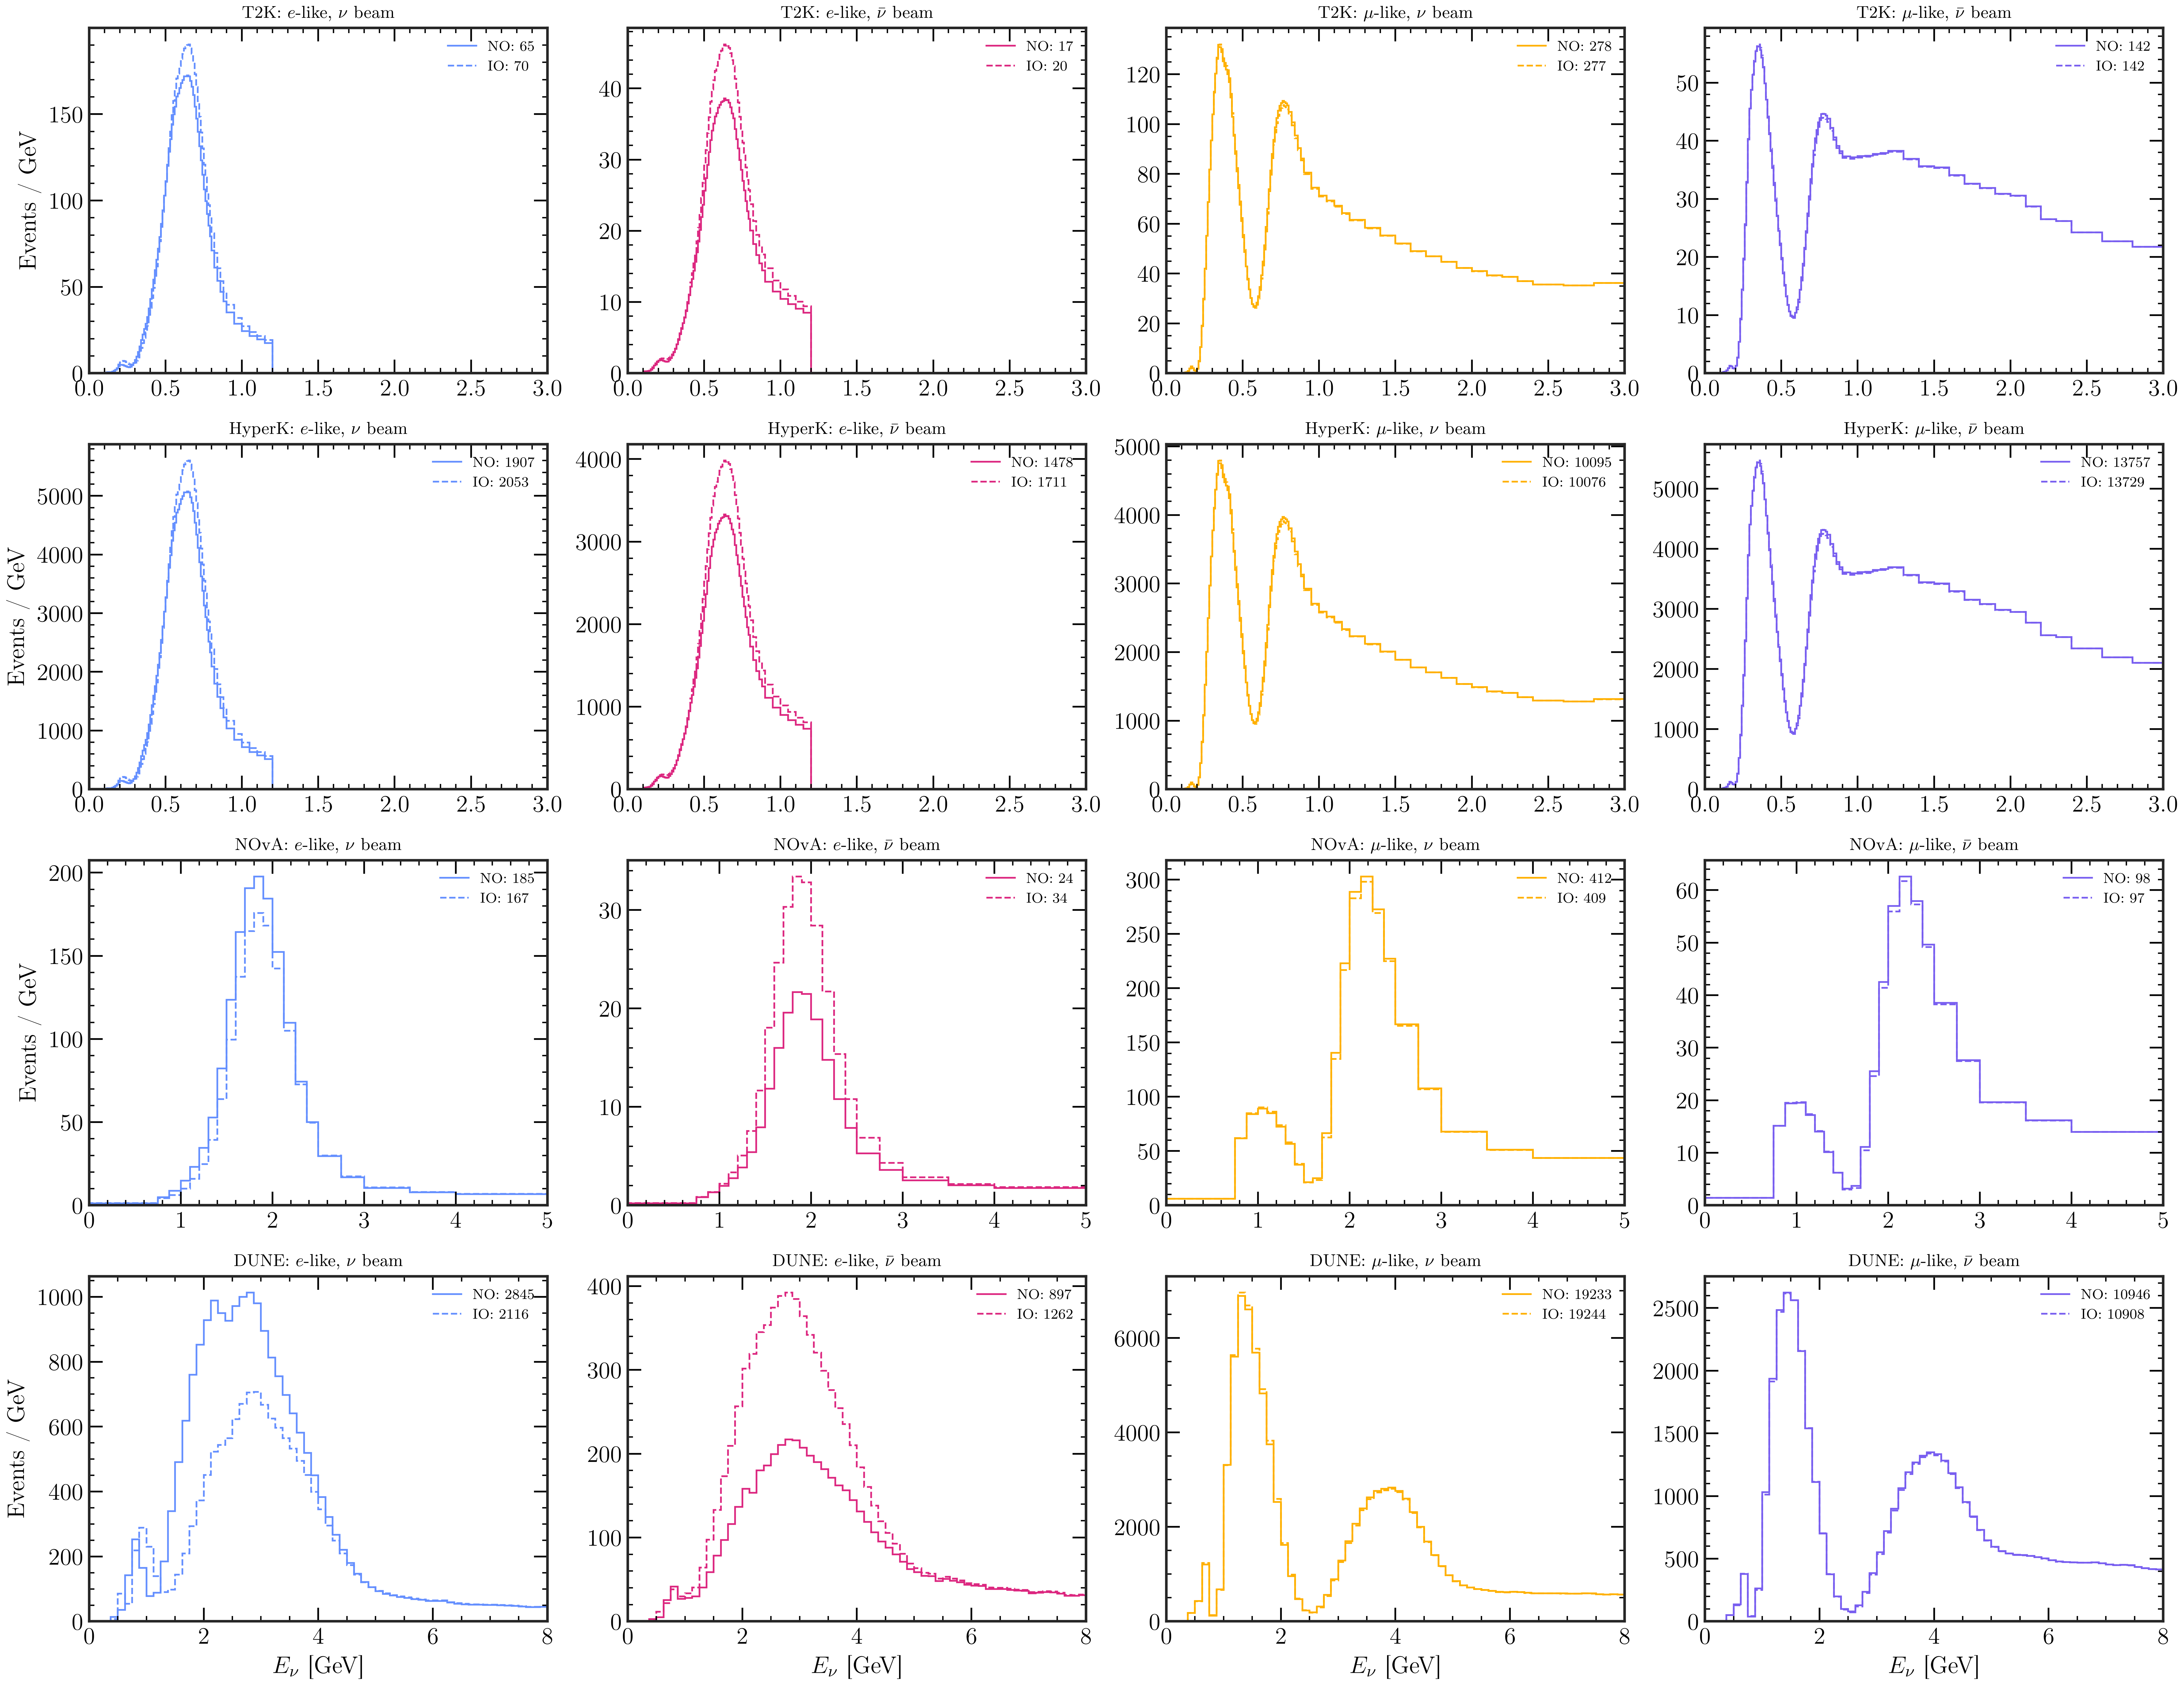

In [4]:
osc = {o: NeutrinoOscillator(o) for o in ("NO", "IO")}
panels = [("FHC", "e_like", r"$e$-like, $\nu$ beam"), ("RHC", "e_like", r"$e$-like, $\bar\nu$ beam"),
          ("FHC", "mu_like", r"$\mu$-like, $\nu$ beam"), ("RHC", "mu_like", r"$\mu$-like, $\bar\nu$ beam")]

fig, axes = plt.subplots(len(EXPERIMENTS), 4, figsize=(18, 14), dpi = 400)
for i, name in enumerate(EXPERIMENTS):
    for o, ls in (("NO", "-"), ("IO", "--")):
        p = predict(name, osc[o])
        w = np.diff(p["edges"])
        for j, (m, smp, title) in enumerate(panels):
            ax = axes[i, j]
            ax.stairs(p[m][smp] / w, p["edges"], color=c[j], ls=ls,
                      label=f"{o}: {p[m][smp].sum():.0f}")
            ax.set_xlim(0, E_MAX[name])
            ax.set_title(f"{name}: {title}", fontsize="small")
            ax.legend(fontsize="x-small")
    axes[i, 0].set_ylabel("Events / GeV")
for ax in axes[-1]:
    ax.set_xlabel(r"$E_\nu$ [GeV]")
plt.tight_layout()
plt.show()

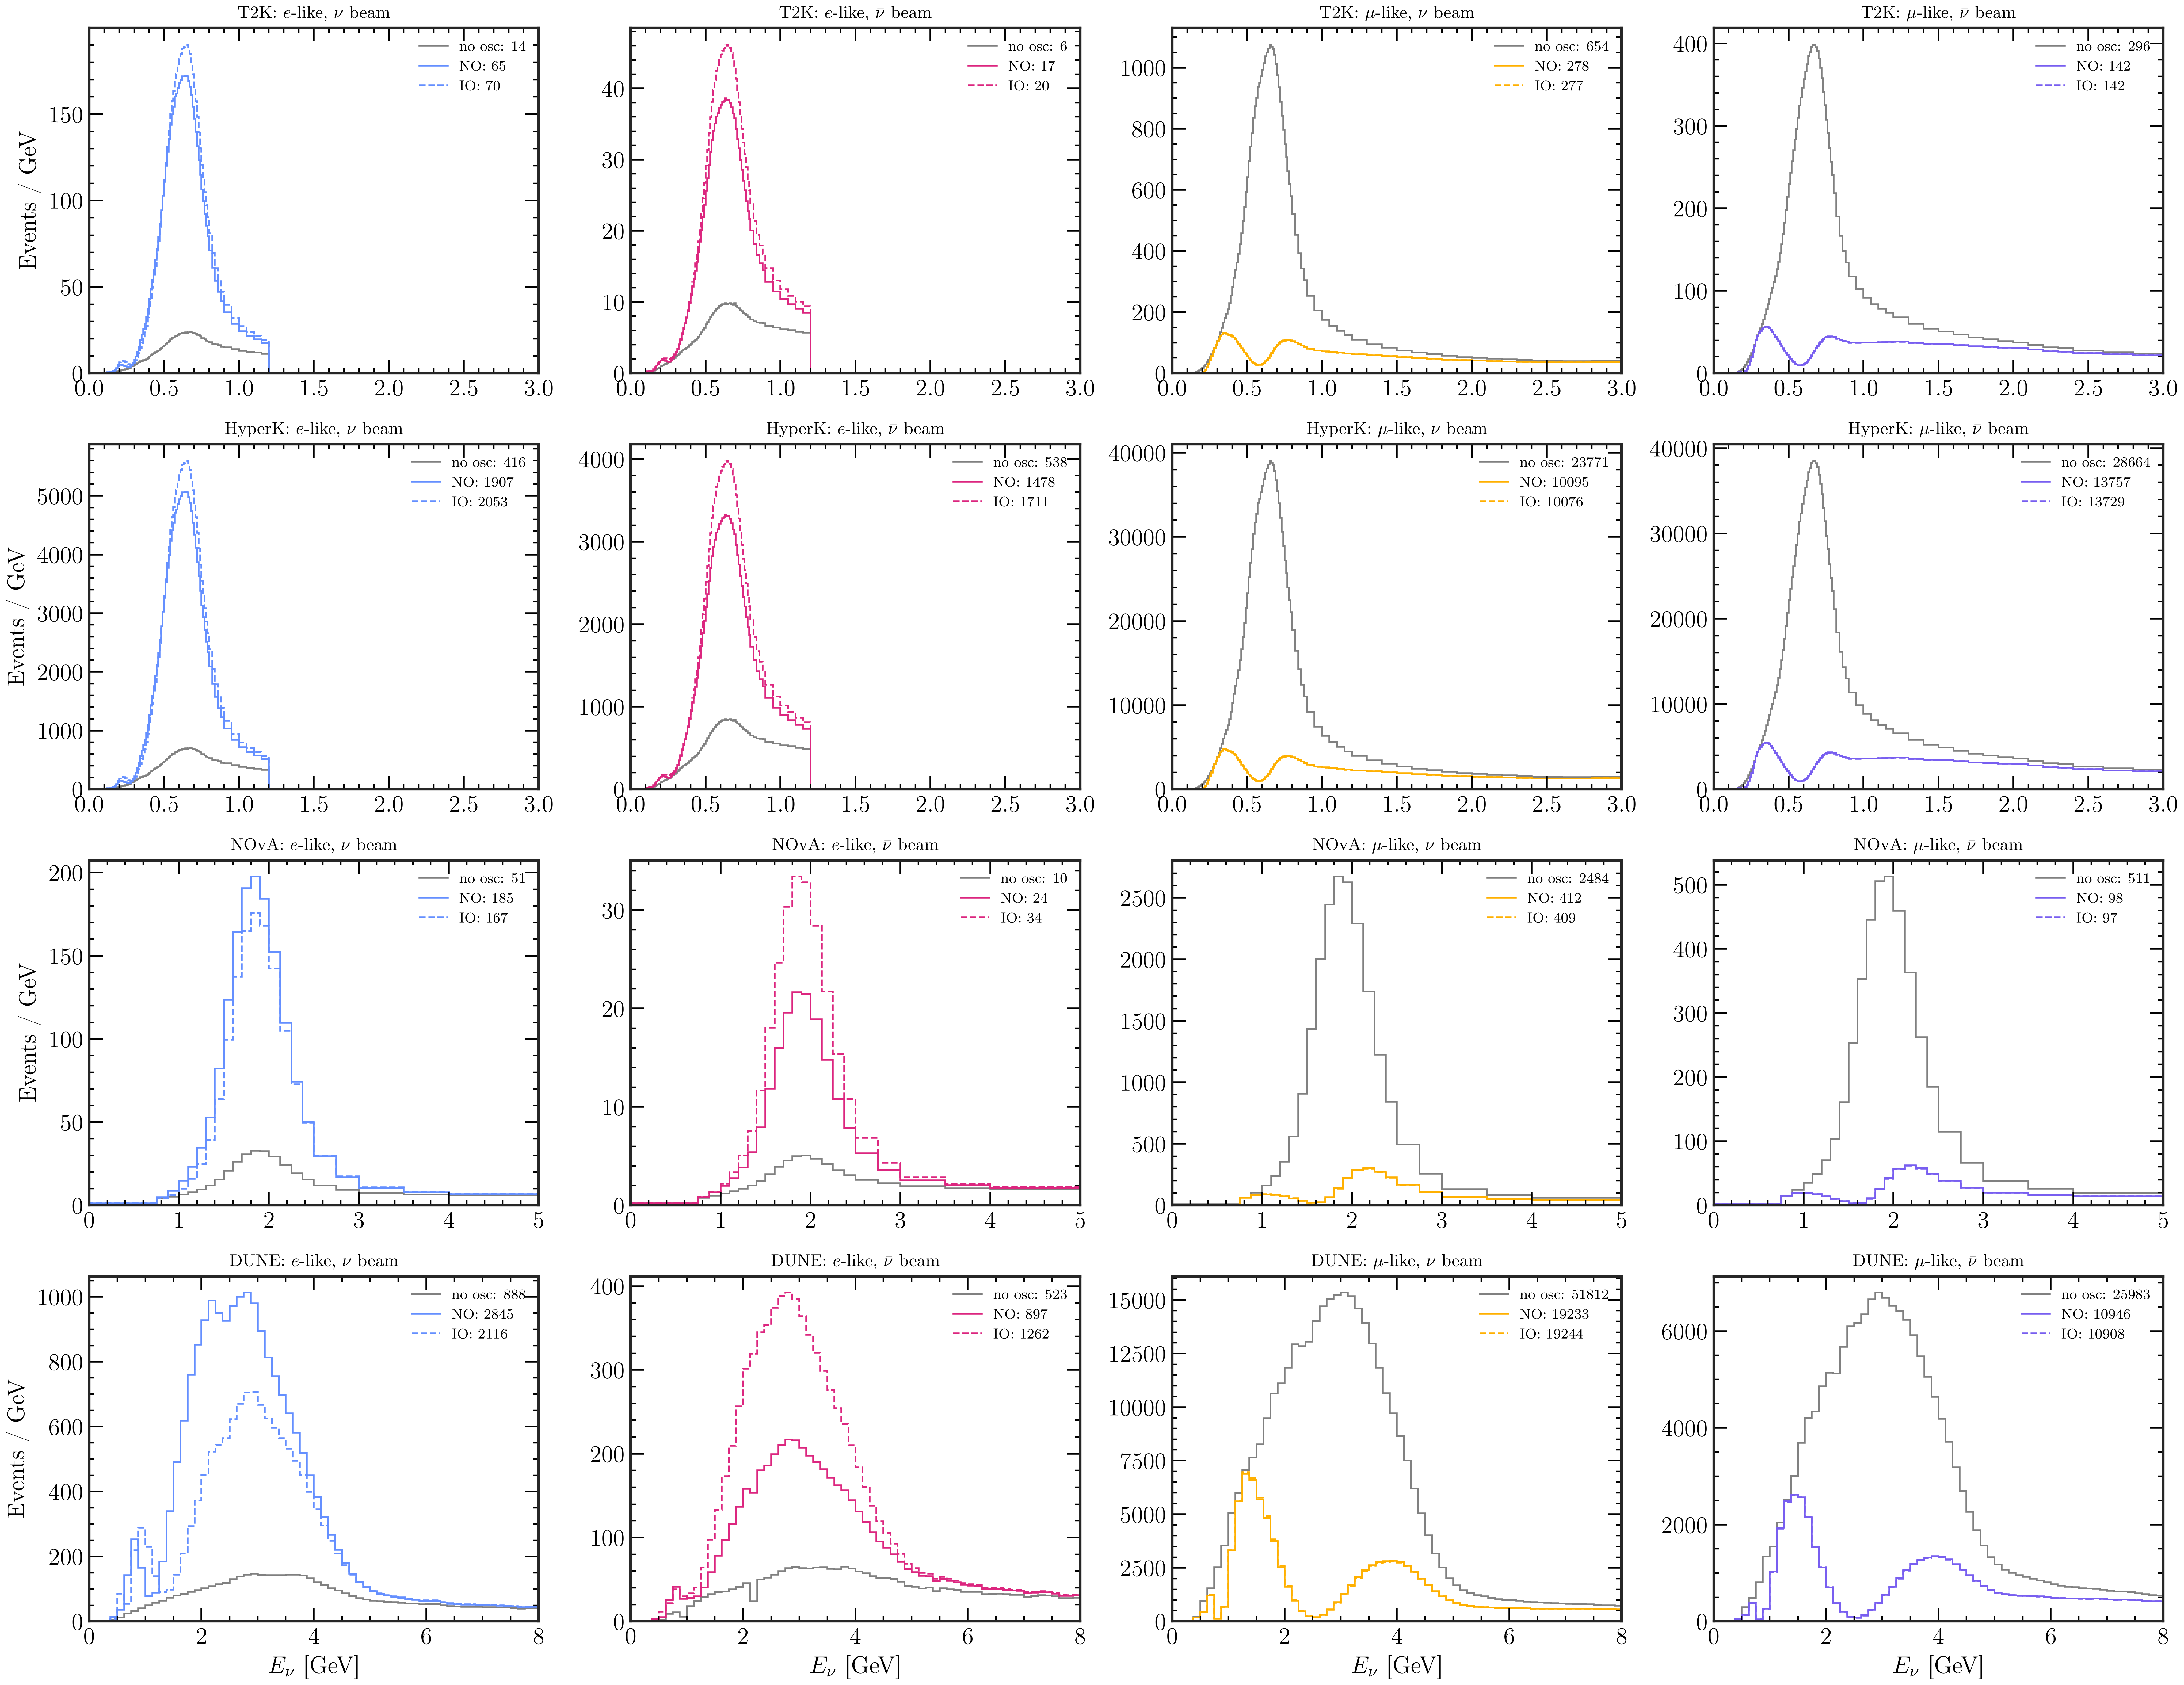

In [5]:
osc = {o: NeutrinoOscillator(o) for o in ("NO", "IO")}
no_osc = NeutrinoOscillator("NO").set_params(s2_12=0, s2_13=0, s2_23=0)   # P = identity

panels = [("FHC", "e_like", r"$e$-like, $\nu$ beam"), ("RHC", "e_like", r"$e$-like, $\bar\nu$ beam"),
          ("FHC", "mu_like", r"$\mu$-like, $\nu$ beam"), ("RHC", "mu_like", r"$\mu$-like, $\bar\nu$ beam")]

fig, axes = plt.subplots(len(EXPERIMENTS), 4, figsize=(18, 14), dpi=400)
for i, name in enumerate(EXPERIMENTS):
    p0 = predict(name, no_osc)                          # unoscillated
    w = np.diff(p0["edges"])
    for j, (m, smp, title) in enumerate(panels):
        axes[i, j].stairs(p0[m][smp] / w, p0["edges"], color="gray", lw=1,
                          label=f"no osc: {p0[m][smp].sum():.0f}")
    for o, ls in (("NO", "-"), ("IO", "--")):
        p = predict(name, osc[o])
        for j, (m, smp, title) in enumerate(panels):
            ax = axes[i, j]
            ax.stairs(p[m][smp] / w, p["edges"], color=c[j], ls=ls,
                      label=f"{o}: {p[m][smp].sum():.0f}")
            ax.set_xlim(0, E_MAX[name])
            ax.set_title(f"{name}: {title}", fontsize="small")
            ax.legend(fontsize="x-small")
    axes[i, 0].set_ylabel("Events / GeV")
for ax in axes[-1]:
    ax.set_xlabel(r"$E_\nu$ [GeV]")
plt.tight_layout()
plt.show()

## 3. Signal and backgrounds of the $e$-like samples

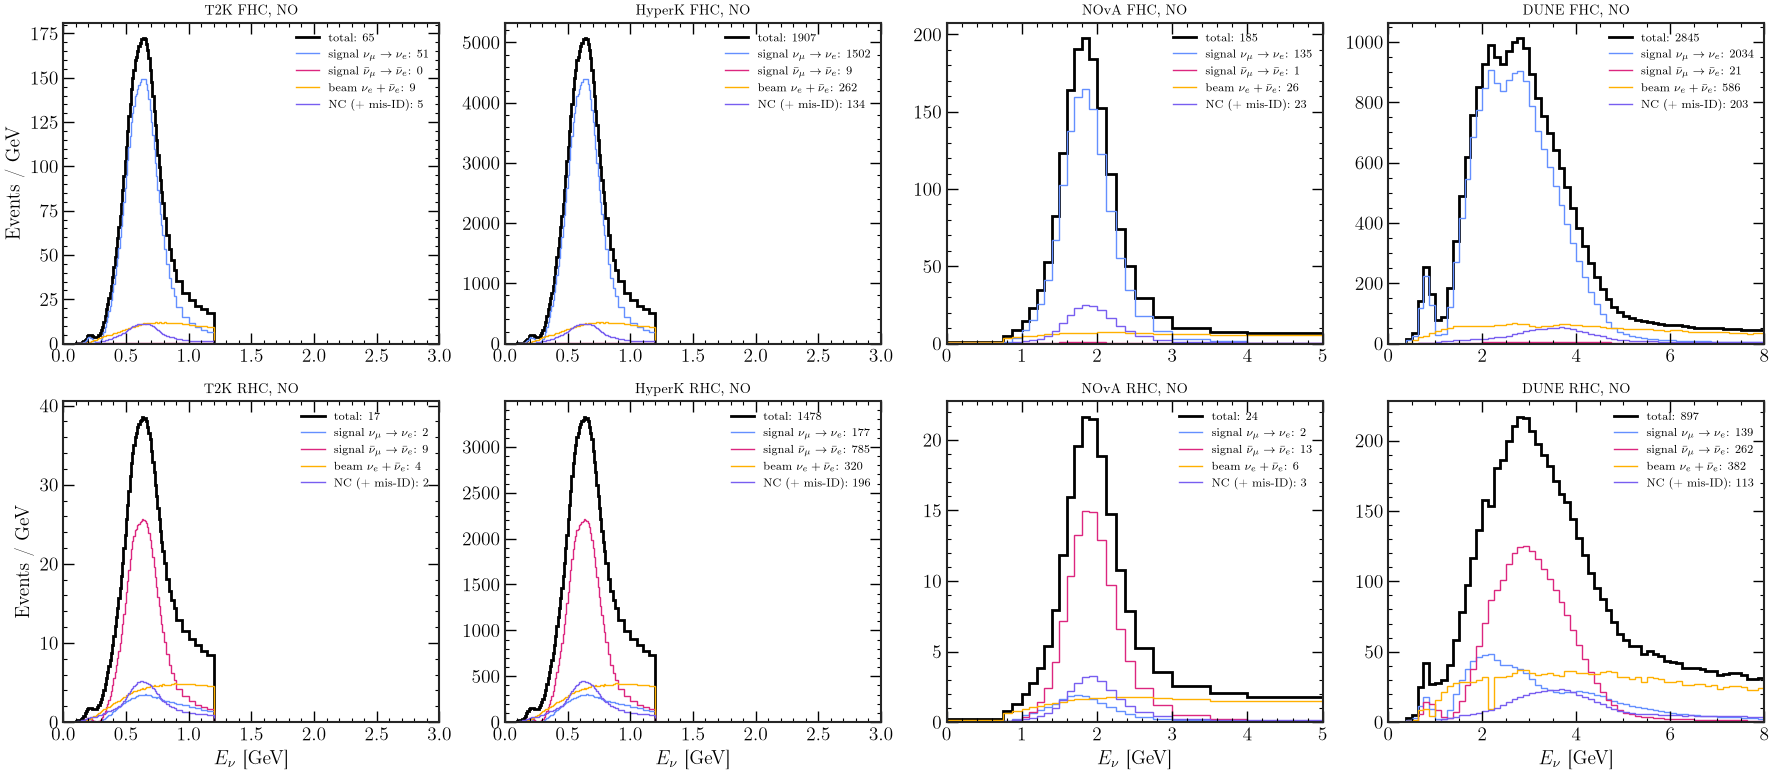

In [6]:
fig, axes = plt.subplots(2, len(EXPERIMENTS), figsize=(18, 8))
groups = [("signal $\\nu_\\mu\\to\\nu_e$", ["numu_e"]), ("signal $\\bar\\nu_\\mu\\to\\bar\\nu_e$", ["numubar_e"]),
          ("beam $\\nu_e+\\bar\\nu_e$", ["nue_e", "nuebar_e"]), ("NC (+ mis-ID)", ["NC_e", "numu_misid_e", "numubar_misid_e"])]
for j, name in enumerate(EXPERIMENTS):
    p = predict(name, osc["NO"])
    w = np.diff(p["edges"])
    for i, m in enumerate(("FHC", "RHC")):
        ax = axes[i, j]
        ax.stairs(p[m]["e_like"] / w, p["edges"], color="k", lw=2, label=f"total: {p[m]['e_like'].sum():.0f}")
        for k, (lab, comps) in enumerate(groups):
            y = sum(p[m][cc] for cc in comps)
            ax.stairs(y / w, p["edges"], color=c[k], label=f"{lab}: {y.sum():.0f}")
        ax.set_xlim(0, E_MAX[name])
        ax.set_title(f"{name} {m}, NO", fontsize="small")
        ax.legend(fontsize="x-small")
    axes[1, j].set_xlabel(r"$E_\nu$ [GeV]")
axes[0, 0].set_ylabel("Events / GeV"); axes[1, 0].set_ylabel("Events / GeV")
plt.tight_layout()
plt.show()

## 4. Bi-event plot for the four experiments

Total $e$-like events in the neutrino vs antineutrino beam when $\delta_{CP}$ varies from $0$ to $2\pi$
(all other parameters at the NuFIT 6.0 best fit of each ordering). Circles: $\delta_{CP}=0$, squares: $\delta_{CP}=90^\circ$.

**Stars: the current global best fit** (NuFIT 6.0: $\delta_{CP}=212^\circ$ for NO, $274^\circ$ for IO), with the
**error bars of each experiment's exposure**: $\sqrt N$ in each beam mode (statistical, $1\sigma$), optionally with a
fractional systematic `SYST` added in quadrature.

| experiment | exposure | error |
|---|---|---|
| T2K | Run 1–9: 14.94e20 POT ($\nu$) + 16.35e20 POT ($\bar\nu$) | **current** |
| NOvA | 2024 analysis: 26.61e20 POT ($\nu$) + 12.5e20 POT ($\bar\nu$) | **current** |
| Hyper-K | 10 yr at 1.3 MW, $\nu:\bar\nu = 1:3$ (Design Report) | **projected** |
| DUNE | 6.5 + 6.5 yr at 1.2 MW (TDR) | **projected** |

If the error bars of the NO and IO stars do not overlap, the experiment separates the two best fits
with that exposure (counting only, no shape information).


T2K     NO: N_nu =    64.8 +-   8.1   N_nubar =    17.1 +-   4.1
T2K     IO: N_nu =    69.8 +-   8.4   N_nubar =    19.8 +-   4.5
HyperK  NO: N_nu =  1907.5 +-  43.7   N_nubar =  1477.6 +-  38.4
HyperK  IO: N_nu =  2053.2 +-  45.3   N_nubar =  1710.7 +-  41.4
NOvA    NO: N_nu =   185.0 +-  13.6   N_nubar =    24.5 +-   4.9
NOvA    IO: N_nu =   166.5 +-  12.9   N_nubar =    34.0 +-   5.8
DUNE    NO: N_nu =  2844.6 +-  53.3   N_nubar =   897.4 +-  30.0
DUNE    IO: N_nu =  2116.1 +-  46.0   N_nubar =  1262.2 +-  35.5


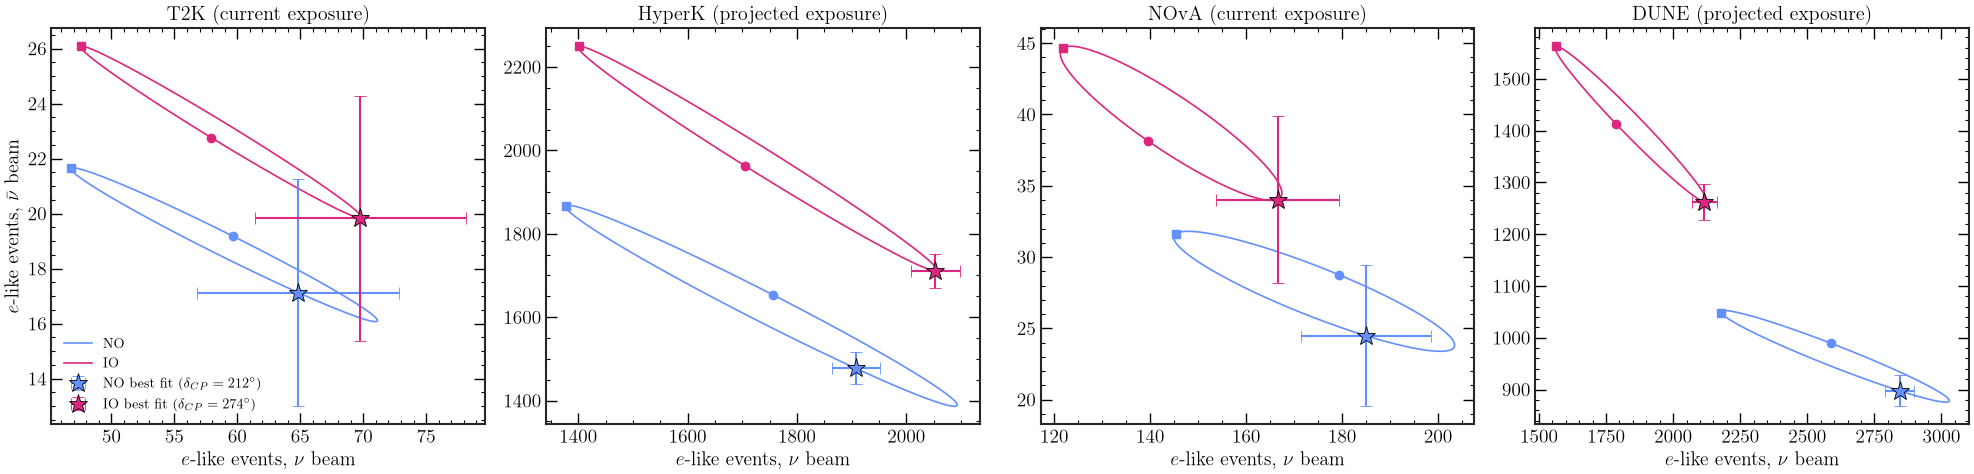

In [7]:
deltas = np.linspace(0, 360, 73)
SYST = 0.0            # fractional systematic added in quadrature to sqrt(N), e.g. 0.05 for 5 %
STATUS = {"T2K": "current", "NOvA": "current", "HyperK": "projected", "DUNE": "projected"}

fig, axes = plt.subplots(1, len(EXPERIMENTS), figsize=(20, 5))
for ax, name in zip(axes, EXPERIMENTS):
    spec = load_fd_spectra(name)
    for i, o in enumerate(("NO", "IO")):
        N = np.array([[predict(name, NeutrinoOscillator(o, delta_cp=d), spectra=spec)[m]["e_like"].sum()
                       for m in ("FHC", "RHC")] for d in deltas])
        ax.plot(N[:, 0], N[:, 1], color=c[i], label=o)
        ax.plot(N[0, 0], N[0, 1], "o", color=c[i])          # delta_CP = 0
        ax.plot(N[18, 0], N[18, 1], "s", color=c[i])        # delta_CP = 90 deg

        bf = NeutrinoOscillator(o)                          # NuFIT 6.0 best fit for this ordering
        Nbf = np.array([predict(name, bf, spectra=spec)[m]["e_like"].sum() for m in ("FHC", "RHC")])
        err = np.sqrt(Nbf + (SYST * Nbf) ** 2)
        ax.errorbar(*Nbf, xerr=err[0], yerr=err[1], fmt="*", ms=14, color=c[i], mec="k", mew=0.6,
                    capsize=4, elinewidth=1.5, zorder=5,
                    label=rf"{o} best fit ($\delta_{{CP}} = {bf.delta_cp:.0f}^\circ$)")
        print(f"{name:7s} {o}: N_nu = {Nbf[0]:7.1f} +- {err[0]:5.1f}   N_nubar = {Nbf[1]:7.1f} +- {err[1]:5.1f}")
    ax.set_title(f"{name} ({STATUS[name]} exposure)")
    ax.set_xlabel(r"$e$-like events, $\nu$ beam")
axes[0].set_ylabel(r"$e$-like events, $\bar\nu$ beam")
axes[0].legend(fontsize="small")
plt.tight_layout()
plt.show()


## 5. Without `nuosc`: the recipe in plain numpy

The files are self-contained: any code that returns $P(E)$ can use them.
Here an example with the two-flavour survival probability for the $\mu$-like sample.

In [8]:
fname = "far_detector_spectra/DUNE_FD_spectra.csv"
cols = [l for l in open(fname) if l.startswith("#")][-1][2:].strip().split(",")   # last comment line = column names
d = dict(zip(cols, np.loadtxt(fname, delimiter=",").T))
E = d["E_center"]
L = 1284.9                                   # km (see the file header)
P_mumu = 1 - 1.0 * np.sin(1.267 * 2.5e-3 * L / E) ** 2      # sin^2(2 theta) = 1, dm2 = 2.5e-3 eV^2
mu_like = P_mumu * d["FHC_numu_mu"] + P_mumu * d["FHC_numubar_mu"] + d["FHC_NC_mu"]
print(f"DUNE FHC mu-like, two-flavour approximation: {mu_like.sum():.0f} events")

DUNE FHC mu-like, two-flavour approximation: 18932 events


## 6. Validation against published numbers

In [9]:
from nuosc.data import t2k_oscillator, load_t2k_oa2019_rates

print("DUNE (NuFIT 6.0 NO): compare with the full GLoBES calculation in dune_tdr_simulation.ipynb")
from nuosc.dune_globes import DUNEGlobes
S = DUNEGlobes().all_samples(osc["NO"])
p = predict("DUNE", osc["NO"])
print(f"   FHC e-like {p['FHC']['e_like'].sum():7.1f} vs {S['nue_app']['total'].sum():7.1f}, "
      f"mu-like {p['FHC']['mu_like'].sum():8.1f} vs {S['numu_dis']['total'].sum():8.1f}")

print("\nT2K Run 1-9, Table XI of arXiv:2101.03779 (in brackets):")
pred, obs = load_t2k_oa2019_rates()
for dcp in sorted(pred):
    p = predict("T2K", t2k_oscillator(dcp))
    print(f"   delta = {dcp:+.2f}: FHC e-like {p['FHC']['e_like'].sum():5.1f} ({pred[dcp]['FHC_e_like']:5.1f}), "
          f"RHC e-like {p['RHC']['e_like'].sum():5.1f} ({pred[dcp]['RHC_e_like']:5.1f}), "
          f"FHC mu-like {p['FHC']['mu_like'].sum():6.1f} ({pred[dcp]['FHC_mu_like']:6.1f})")
print(f"   observed: FHC e-like {obs['FHC_e_like']:.0f}, RHC e-like {obs['RHC_e_like']:.0f}, FHC mu-like {obs['FHC_mu_like']:.0f}")

DUNE (NuFIT 6.0 NO): compare with the full GLoBES calculation in dune_tdr_simulation.ipynb
   FHC e-like  2844.6 vs  2844.6, mu-like  19233.4 vs  19233.4

T2K Run 1-9, Table XI of arXiv:2101.03779 (in brackets):
   delta = -1.57: FHC e-like  74.4 ( 74.4), RHC e-like  17.1 ( 17.1), FHC mu-like  272.4 ( 272.4)
   delta = +0.00: FHC e-like  62.8 ( 62.2), RHC e-like  20.0 ( 19.6), FHC mu-like  272.1 ( 272.0)
   delta = +1.57: FHC e-like  50.6 ( 50.6), RHC e-like  22.5 ( 21.7), FHC mu-like  272.4 ( 272.4)
   delta = +3.14: FHC e-like  62.2 ( 62.7), RHC e-like  19.6 ( 19.3), FHC mu-like  272.8 ( 272.8)
   observed: FHC e-like 75, RHC e-like 15, FHC mu-like 243
